# Projeto 2 — Sprint 1
## Depois da intervenção e comparação

**Variável:** Tempo de carregamento (minutos).  
**Planilha 2:** 100 observações posteriores à intervenção.  
Este notebook atende às Questões 7.1 a 7.4 e 8. Os dados originais são mantidos sem alterações. Execute as células em ordem no Google Colab com as duas planilhas carregadas.

## 1. Bibliotecas e dados

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

ARQUIVO_ANTES = "Planilha1_Tempo de carregamento de caminhões com grãos.xlsx"
ARQUIVO_DEPOIS = "Planilha2_Tempo de carregamento de caminhões com grãos.xlsx"
COLUNA = "Tempo de carregamento (min)"

df_antes = pd.read_excel(ARQUIVO_ANTES)
df_depois = pd.read_excel(ARQUIVO_DEPOIS)
antes = pd.to_numeric(df_antes[COLUNA], errors="coerce").dropna()
depois = pd.to_numeric(df_depois[COLUNA], errors="coerce").dropna()
print(f"Antes: {len(antes)} observações; Depois: {len(depois)} observações")

Antes: 300 observações; Depois: 100 observações


## Questão 7.1 — Situação, intervenção e objetivo

**Situação:** Antes da intervenção, o tempo médio de carregamento era de aproximadamente 31,89 minutos, com desvio-padrão de 3,82 minutos. Tempos elevados podem aumentar a espera dos caminhões, reduzir a capacidade de atendimento e gerar atrasos na operação. Os dados mostram a duração do processo, mas não identificam sozinhos a causa dos tempos mais altos.

**Ação/intervenção proposta:** Padronizar a preparação do carregamento antes da chegada/posicionamento do caminhão, com checklist de disponibilidade dos grãos, equipamentos e equipe, além de organizar previamente a sequência de atendimento. Essa é uma proposta plausível para o projeto; o grupo deve ajustá-la caso tenha recebido uma descrição específica da intervenção realmente realizada.

**Objetivo (pergunta):** A padronização e a preparação prévia do processo conseguem reduzir o tempo de carregamento dos caminhões com grãos, aumentando a proporção de carregamentos concluídos em até 30 minutos?



## Questão 7.2 — Gráficos após a intervenção

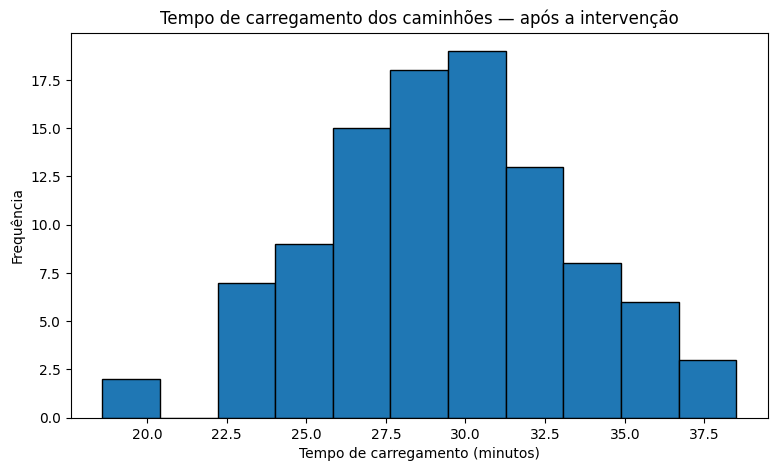

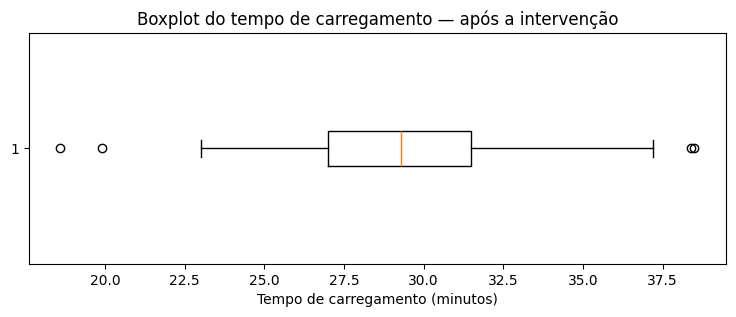

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(depois, bins="auto", edgecolor="black")
ax.set(title="Tempo de carregamento dos caminhões — após a intervenção",
       xlabel="Tempo de carregamento (minutos)", ylabel="Frequência")
plt.show()

fig, ax = plt.subplots(figsize=(9, 3))
ax.boxplot(depois, vert=False)
ax.set(title="Boxplot do tempo de carregamento — após a intervenção",
       xlabel="Tempo de carregamento (minutos)")
plt.show()

## Questão 7.3 — Média e desvio-padrão após a intervenção

In [ ]:
media_antes, dp_antes = antes.mean(), antes.std(ddof=1)
media_depois, dp_depois = depois.mean(), depois.std(ddof=1)
print(f"Média após: {media_depois:.4f} minutos")
print(f"Desvio-padrão amostral após: {dp_depois:.4f} minutos")

Média após: 29.3100 minutos
Desvio-padrão amostral após: 3.8184 minutos


## Questão 7.4 — Quantidade de observações em um intervalo relacionado ao objetivo

Para avaliar o objetivo de reduzir a duração, adotamos provisoriamente o intervalo **[20, 30] minutos**: 30 minutos funciona como meta máxima de tempo, e 20 minutos como limite inferior da faixa de referência escolhida pelo grupo. A escolha de 30 minutos deve ser justificada na Questão 1 como meta operacional proposta e validada com o docente/empresa, pois o material fornecido não informa um padrão oficial de tempo. O intervalo de 20 a 30 minutos também permite comparar a proporção de carregamentos dentro da faixa antes e depois.

In [ ]:
# Intervalo-alvo para a análise (minutos)
a = 20
b = 30

if a > b:
    raise ValueError("O limite a deve ser menor ou igual a b.")

contagem = int(depois.between(a, b, inclusive="both").sum())
proporcao = contagem / len(depois)
print(f"Pergunta: quantos carregamentos após a intervenção levaram entre {a} e {b} minutos?")
print(f"Quantidade: {contagem} de {len(depois)} observações")
print(f"Proporção: {proporcao:.2%}")

Pergunta: quantos carregamentos após a intervenção levaram entre 20 e 30 minutos?
Quantidade: 57 de 100 observações
Proporção: 57.00%


## Questão 8 — Comparação antes e depois

In [ ]:
# Indicadores descritivos: média e proporção no intervalo-alvo
def resumo(x, nome):
    dentro = x.between(a, b, inclusive="both")
    return {
        "Cenário": nome,
        "n": len(x),
        "Média (min)": x.mean(),
        "Desvio-padrão (min)": x.std(ddof=1),
        f"Quantidade em [{a}, {b}]": int(dentro.sum()),
        f"Proporção em [{a}, {b}]": dentro.mean()
    }

comparacao = pd.DataFrame([resumo(antes, "Antes"), resumo(depois, "Depois")])
display(comparacao.style.format({"Média (min)":"{:.3f}", "Desvio-padrão (min)":"{:.3f}",
                                  f"Proporção em [{a}, {b}]":"{:.2%}"}))

,Cenário,n,Média (min),Desvio-padrão (min),"Quantidade em [20, 30]","Proporção em [20, 30]"
0,Antes,300,31.887,3.818,97,32.33%
1,Depois,100,29.310,3.818,57,57.00%


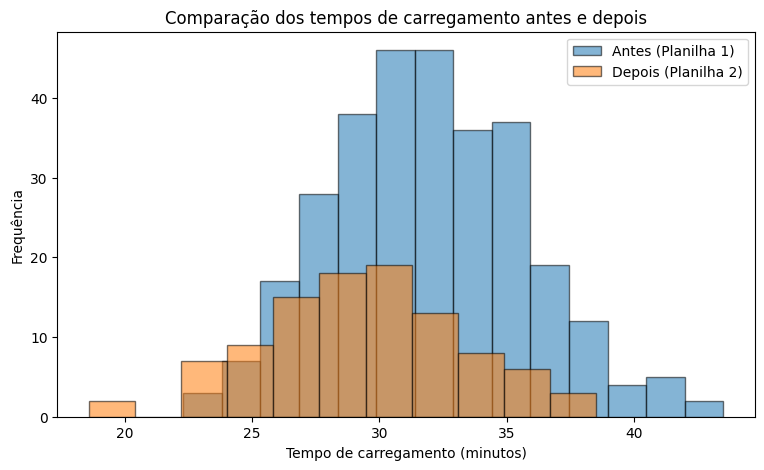

/tmp/ipykernel_515/1818176261.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([antes, depois], labels=["Antes", "Depois"], vert=True)


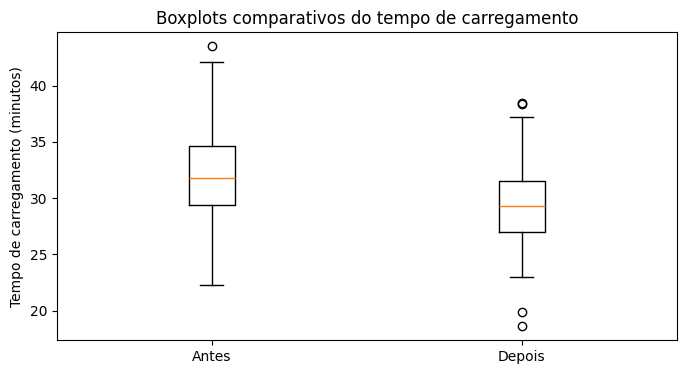

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(antes, bins="auto", alpha=.55, edgecolor="black", label="Antes (Planilha 1)")
ax.hist(depois, bins="auto", alpha=.55, edgecolor="black", label="Depois (Planilha 2)")
ax.set(title="Comparação dos tempos de carregamento antes e depois",
       xlabel="Tempo de carregamento (minutos)", ylabel="Frequência")
ax.legend()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot([antes, depois], labels=["Antes", "Depois"], vert=True)
ax.set(title="Boxplots comparativos do tempo de carregamento",
       ylabel="Tempo de carregamento (minutos)")
plt.show()

### Critérios e interpretação preliminar

**Pergunta da Questão 8:** Há indícios de que a intervenção proposta/realizada contribuiu para reduzir o tempo de carregamento dos caminhões com grãos?

**Critério 1 — média do tempo:** comparar a média antes e depois. A média passou de 31,89 min para 29,31 min, uma redução descritiva de 2,58 min.

**Critério 2 — proporção no intervalo-alvo [20, 30] min:** antes, 97 de 300 carregamentos (32,33%) estavam nessa faixa; depois, 57 de 100 (57,00%). Houve aumento de 24,67 pontos percentuais na proporção dentro da faixa-alvo.

**Conclusão preliminar:** os dois critérios apontam na direção desejada: a média diminuiu e aumentou a proporção de carregamentos entre 20 e 30 minutos. Portanto, os dados apresentam indícios descritivos de melhora após a intervenção. Esta é uma análise preliminar; não permite afirmar causalidade nem comprovar estatisticamente a eficácia da intervenção.